In [1]:
import dask
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.patches as patches
import numpy as np
import seaborn as sns
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmcrameri as cm
import os
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
import matplotlib.patches as patches
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
import warnings
from cmcrameri import cm
import cfgrib
import glob

import babet as bb
import atmicp

warnings.filterwarnings("ignore", category=FutureWarning)
dask.config.set(**{'array.slicing.split_large_chunks': True})

In [2]:
atmicp.style.set_style()

# climate scenario colours from the shared style
CLIM = {'pi': atmicp.style.climate_color('1870'),        # blue
        'curr': atmicp.style.climate_color('present'),   # grey
        'incr': atmicp.style.climate_color('future1')}   # orange

LABEL = {'pi': 'pre-industrial', 'curr': 'current', 'incr': 'increased'}

# one linestyle per perturbation, so climate stays the only thing colour encodes
LS = {'iterated': '-.',
      'iterated_short': ':',
      'tq': '--',
      'ocean': '-',
      'none': '-'}

PERT_LABEL = {'iterated': 'iterated',
              'iterated_short': 'iterated, short',
              'tq': 'delta t+q',
              'ocean': 'ocean only',
              'none': 'unperturbed'}

# marker per perturbation, for the line plots where linestyle is already used
# to tell land from ocean
MARKER = {'iterated': 'o', 'iterated_short': 's', 'none': '^'}

# diverging ramp for the delta maps, as in notebooks 06 and 08
DIVERGING = cm.vik

In [3]:
SCALE = {'t': 1.0, 'q': 1e6}
SYMBOL = {'t': 'T', 'q': 'q'}
UNITS = {'t': 'K', 'q': r'mg kg$^{-1}$'}

def plot_maps(da, col, proj=ccrs.PlateCarree(), col_wrap=4, cmap=DIVERGING,
              vlim=None, title=None, size=1.3, aspect=2.0, **kwargs):
    """
    Facet map plot with coastlines.

    Longitudes are shifted from 0..359 to -180..180 first, otherwise half the
    field is drawn outside the map and misses the coastlines.

    The projection is plate carree rather than Robinson because cartopy has to
    transform the 181x360 quad mesh panel by panel when the two differ, which
    costs about 4 s a panel -- half a minute for a seven panel grid and minutes
    for a thirty panel one. Pass proj=ccrs.Robinson() where it is worth the
    wait; the small figures below do.

    `vlim` defaults to the 99th percentile of |da|, symmetric about zero: a
    handful of extreme grid points would otherwise flatten the whole colour
    scale, and the deltas span four orders of magnitude between the surface and
    the stratosphere so a fixed scale cannot serve both.

    `size` and `aspect` are the height in inches and the width/height ratio of
    one panel. A global field is twice as wide as it is tall while the default
    facet cell is nearly square, which leaves a band of white between every row
    of a thirty panel grid.
    """
    da = da.assign_coords(longitude=(((da.longitude + 180) % 360) - 180)).sortby('longitude')

    if vlim is None:
        vlim = float(np.nanpercentile(np.abs(da), 99))

    p = da.plot(col=col, col_wrap=col_wrap,
                transform=ccrs.PlateCarree(),  # the data itself is on a regular lat/lon grid
                subplot_kws={'projection': proj},
                cmap=cmap, vmin=-vlim, vmax=vlim, size=size, aspect=aspect,
                rasterized=True,  # keeps the vector PDF small and quick to write
                **kwargs)

    for ax in p.axes.flat:
        ax.coastlines(resolution='110m', linewidth=0.5, color='k')
        ax.set_global()

    if title is not None:
        # on a FacetGrid plt.title lands on the last subplot, not the figure.
        # y is in figure coordinates, so a fixed value sits on top of the panel
        # titles of a one row grid and miles above a five row one; offsetting by
        # a third of an inch keeps the same gap whatever the grid.
        nrow = int(np.ceil(da[col].size / col_wrap))
        p.fig.suptitle(title, y=1 + 0.35 / (nrow * size),
                       fontsize=atmicp.style.scaled(atmicp.style.FS_TITLE, p.fig))

    return p


def delta_label(d):
    """Colourbar label for a delta of variable `var`."""
    var = d.attrs['var']
    return rf'$\Delta${SYMBOL.get(var, var)} / {UNITS.get(var, d.attrs["units"])}'


def figure_title(d, extra=''):
    exp, ref = d.attrs['expver'], d.attrs['ref_expver']
    lead = 'initialisation' if d.attrs['time'] == 0 else f'+{d.attrs["time"]:.0f} h'
    return f'{exp} - {ref}, {SYMBOL.get(d.attrs["var"], d.attrs["var"])} at {lead}{extra}'


def balanced_wrap(n, most=6):
    """Column count for `n` panels that avoids a last row holding one panel."""
    wrap = min(n, most)
    while wrap > 2 and n % wrap == 1:
        wrap -= 1
    return wrap

# Import iterated data

In [4]:
ifs_pl = atmicp.Data.get_ifs_data(levtype='pl', res='GLO100',
                                   variables=['t', 'q'])

Loading 3 file(s) for b2vj (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/pl/cf


Loading 3 file(s) for b2vj (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/pl/pf
Loading 3 file(s) for b2vr (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/pl/cf
Loading 3 file(s) for b2vr (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/pl/pf
Loading 3 file(s) for b2vl (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/pl/cf
Loading 3 file(s) for b2vl (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/pl/pf
Loading 3 file(s) for b2vo (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/pl/cf
Loading 3 file(s) for b2vo (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/pl/pf
Loading 3 file(s) for b2ut (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/curr/GLO100/pl/cf
Loading 3 file(s) for b2ut (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/curr/GLO100/pl/pf
Loading 3 file(s) for b2vk (cf) from /gf5/

/home/e/ermis/ATMICP/atmicp/data.py:256: UserWarning: b2vq: missing inidates ['b2vq_2021-06-22.nc', 'b2vq_2021-06-26.nc'] in /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/incr/GLO100/pl/cf
  warnings.warn(
/home/e/ermis/ATMICP/atmicp/data.py:256: UserWarning: b2vq: missing inidates ['b2vq_2021-06-22.nc', 'b2vq_2021-06-26.nc'] in /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/incr/GLO100/pl/pf
  warnings.warn(


Loading 3 file(s) for b2vm (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/incr/GLO100/pl/pf
Loading 3 file(s) for b2vn (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/incr/GLO100/pl/cf
Loading 3 file(s) for b2vn (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/incr/GLO100/pl/pf


In [5]:
ifs_sfc = atmicp.Data.get_ifs_data(levtype='sfc', res='GLO100',
                                   variables=['t2m', 'tcwv'])

Loading 3 file(s) for b2vj (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/sfc/cf
Loading 3 file(s) for b2vj (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/sfc/pf
Loading 3 file(s) for b2vr (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/sfc/cf
Loading 3 file(s) for b2vr (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/sfc/pf
Loading 3 file(s) for b2ut (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/curr/GLO100/sfc/cf


/home/e/ermis/ATMICP/atmicp/data.py:192: UserWarning: No files found for b2vl (pi, GLO100, sfc) on the requested inidates - skipping this experiment.
  warnings.warn(
/home/e/ermis/ATMICP/atmicp/data.py:192: UserWarning: No files found for b2vo (pi, GLO100, sfc) on the requested inidates - skipping this experiment.
  warnings.warn(


Loading 3 file(s) for b2ut (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/curr/GLO100/sfc/pf
Loading 3 file(s) for b2vk (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/incr/GLO100/sfc/cf
Loading 3 file(s) for b2vk (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/incr/GLO100/sfc/pf
Loading 3 file(s) for b2vq (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/incr/GLO100/sfc/cf
Loading 3 file(s) for b2vq (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/incr/GLO100/sfc/pf


/home/e/ermis/ATMICP/atmicp/data.py:192: UserWarning: No files found for b2vm (incr, GLO100, sfc) on the requested inidates - skipping this experiment.
  warnings.warn(
/home/e/ermis/ATMICP/atmicp/data.py:192: UserWarning: No files found for b2vn (incr, GLO100, sfc) on the requested inidates - skipping this experiment.
  warnings.warn(


In [6]:
COV = atmicp.data.Data.survey()
ifs_iter = atmicp.data.Data.load_iterations()

In [7]:
# what actually got retrieved, per experiment
report = pd.DataFrame([
    {'expver': expver,
     'climate': row['climate'],
     'perturbation': row['perturbation'],
     'cf': row['n_cf'],
     'pf': row['n_pf'],
     'first': row['inidates'][0] if row['inidates'] else '-',
     'last': row['inidates'][-1] if row['inidates'] else '-',
     'levels': '/'.join(str(lev) for lev in row['levels']) or '-',
     'levels in some files only':
         '/'.join(str(lev) for lev in set(row['levels_any']) - set(row['levels'])) or '-'}
    for expver, row in COV.items()]).set_index('expver')

# the (climate, perturbation) combinations that loaded, as in notebook 08
present = [(row['climate'], row['perturbation'])
           for row in COV.values() if row['inidates']]

print(report.to_string())
print()
print('loaded:', present)

       climate    perturbation  cf  pf       first        last               levels levels in some files only
expver                                                                                                       
b2vj        pi        iterated  30  30  2021-05-28  2021-06-26  50/200/500/850/1000                         -
b2vr        pi  iterated_short  23  23  2021-06-04  2021-06-26  50/200/500/850/1000                         -
b2ut      curr            none  30  30  2021-05-28  2021-06-26  50/200/500/850/1000                         -
b2vk      incr        iterated  30  30  2021-05-28  2021-06-26  50/200/500/850/1000                         -
b2vq      incr  iterated_short  23  23  2021-06-04  2021-06-26  50/200/500/850/1000                         -

loaded: [('pi', 'iterated'), ('pi', 'iterated_short'), ('curr', 'none'), ('incr', 'iterated'), ('incr', 'iterated_short')]


# Delta plots 

In [8]:
def bootstrap_significance(warm, cold, dim='number', n_boot=1000, alpha=0.05,
                           paired=True, seed=0):
    """
    Ensemble-mean difference `warm` - `cold`, and where it differs from zero.

    The members along `dim` are resampled with replacement `n_boot` times and the
    difference of the ensemble means is recomputed for every draw. A point is
    significant where the central 1 - `alpha` interval of those differences
    excludes zero.

    `paired=True` draws one set of member numbers and uses it for both ensembles,
    which is resampling the member-wise differences. Member n of every experiment
    starts from the same initial perturbation, so this removes the spread the two
    runs have in common. `paired=False` resamples the two ensembles independently
    and so measures the difference against the full ensemble spread.

    A draw is held as a weight per member (how often it was picked, over the
    ensemble size) rather than as a list of member indices, which turns all the
    resampled means into one matrix product.

    With 11 members the percentile interval is a little too narrow: on pure noise
    a nominal 5% test flags about 10% of the points.

    Returns (diff, significant) on the dimensions of the inputs without `dim`.
    """
    # paired members have to be the same members; otherwise only the grid is matched
    warm, cold = xr.align(warm, cold, join='inner', exclude=[] if paired else [dim])
    rng = np.random.default_rng(seed)

    def weights(n):
        return (rng.multinomial(n, np.full(n, 1 / n), size=n_boot) / n).astype('float32')

    def members(da):
        return da.transpose(dim, ...).values.reshape(da.sizes[dim], -1)

    if paired:
        # differenced before the cast: a 1 K signal on a 300 K field is at the
        # edge of what float32 resolves
        delta = (members(warm) - members(cold)).astype('float32')
        boot = weights(len(delta)) @ delta
    else:
        a, b = members(warm).astype('float32'), members(cold).astype('float32')
        boot = weights(len(a)) @ a - weights(len(b)) @ b

    lo, hi = np.quantile(boot, [alpha / 2, 1 - alpha / 2], axis=0)

    diff = warm.mean(dim) - cold.mean(dim)
    significant = diff.copy(data=((lo > 0) | (hi < 0)).reshape(diff.shape))

    return diff, significant

In [9]:
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap

MEMBERS = slice(0, 10)          # the control and the first ten perturbed members
COLUMNS = ['iterated', 'tq']    # 'tq' is the ERA5 delta run
P_TICKS = [1000, 850, 700, 500, 300, 200]
LAT_TICKS = {-60: '60°S', -30: '30°S', 0: '0°', 30: '30°N', 60: '60°N'}


def initial_state(da, climate, perturbation, inidate):
    """Members 0-10 of one experiment at its initial time, or None if it is not on disk.

    'time' is valid time, so the step at `inidate` is the initial state.
    """
    if climate not in da.climate.values or perturbation not in da.perturbation.values:
        return None

    da = da.sel(climate=climate, perturbation=perturbation, inidate=inidate,
                time=inidate, number=MEMBERS).load()

    # the concat NaN-fills experiments that were only partly retrieved
    return None if bool(da.isnull().all()) else da


def centred(da):
    """Longitudes shifted from 0..359 to -180..180, as in plot_maps."""
    return da.assign_coords(longitude=(((da.longitude + 180) % 360) - 180)).sortby('longitude')


def signal_at_init(warm, cold, inidate, n_boot=1000, paired=True):
    """Climate change signal `warm` - `cold` in the initial conditions of one
    initialisation, the iterated run on the left and the ERA5 delta run on the right.

    `warm` and `cold` are climates, given in the direction of warming ('curr' - 'pi',
    'incr' - 'curr'); as in notebook 10 the perturbation of a column applies to
    whichever of the two is not 'curr', which is always the unperturbed run.

    The rows are temperature at 1000 hPa, total column water vapour and the
    zonal-mean temperature on pressure levels, all as the mean over members 0-10.
    On the maps the points where the bootstrap cannot tell the difference from zero
    are hatched. A panel whose run has not been retrieved is left empty.

    Each row shares one colour scale between the two columns, symmetric about zero
    and capped at the 99th percentile of the absolute difference as in plot_maps.
    """
    inidate = np.datetime64(inidate, 'ns')
    date = np.datetime_as_string(inidate, unit='D')

    loaded = {}

    def pair(da, pert):
        states = []
        for climate in (warm, cold):
            # the unperturbed run is the same in both columns: read it once
            key = (da.name, climate, 'none' if climate == 'curr' else pert)
            if key not in loaded:
                loaded[key] = initial_state(da, *key[1:], inidate)
            states.append(loaded[key])
        return None if any(state is None for state in states) else states

    # fields[row][pert] is the difference to draw, masks[row][pert] where it is significant
    fields, masks = [{}, {}, {}], [{}, {}]
    for pert in COLUMNS:
        t = pair(ifs_pl.t, pert)
        if t is not None:
            fields[0][pert], masks[0][pert] = bootstrap_significance(
                t[0].sel(level=1000), t[1].sel(level=1000), n_boot=n_boot, paired=paired)
            fields[2][pert] = (t[0].mean('number') - t[1].mean('number')).mean('longitude')

        tcwv = pair(ifs_sfc.tcwv, pert)
        if tcwv is not None:
            fields[1][pert], masks[1][pert] = bootstrap_significance(
                *tcwv, n_boot=n_boot, paired=paired)

    for name, mask in zip(['T1000', 'tcwv'], masks):
        for pert, significant in mask.items():
            print(f'{date} {warm}-{cold} {name} {pert}: '
                  f'{float(significant.mean()):.0%} of the map significant')

    # the height that lets a 2:1 global map fill the width of its cell, so the maps
    # line up with the sections underneath
    fig = plt.figure(figsize=(atmicp.style.REF_WIDTH, 5.9))
    gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1.15], left=0.08, right=0.89,
                          top=0.91, bottom=0.07, wspace=0.06, hspace=0.16)
    fs = atmicp.style.scaled(atmicp.style.FS_LABEL, fig)
    fs_tick = atmicp.style.scaled(atmicp.style.FS_TICK, fig)

    labels = [r'$\Delta$T 1000 hPa (K)', r'$\Delta$tcwv (kg m$^{-2}$)',
              r'$\Delta$T zonal mean (K)']
    cmaps = [DIVERGING, cm.broc_r, DIVERGING]
    axes = np.empty((3, 2), dtype=object)

    for row in range(3):
        if not fields[row]:
            continue
        vlim = float(np.nanpercentile(
            np.abs(np.concatenate([da.values.ravel() for da in fields[row].values()])), 99))

        for col, pert in enumerate(COLUMNS):
            on_map = row < 2
            ax = axes[row, col] = fig.add_subplot(
                gs[row, col], projection=ccrs.PlateCarree() if on_map else None)

            if on_map:
                ax.coastlines(resolution='110m', linewidth=0.4, color=atmicp.style.INK)
                ax.set_global()
            else:
                ax.set_yscale('log')
                ax.set_ylim(P_TICKS[0], P_TICKS[-1])
                ax.set_yticks(P_TICKS)
                ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
                ax.yaxis.set_minor_locator(mticker.NullLocator())
                ax.set_xlim(-90, 90)
                ax.set_xticks(list(LAT_TICKS), list(LAT_TICKS.values()))
                # the shared style draws no tick marks; both axes carry them here
                ax.tick_params(bottom=True, left=True, length=3, width=0.8,
                               labelsize=fs_tick, labelleft=col == 0)
                ax.set_ylabel('Pressure (hPa)' if col == 0 else '', fontsize=fs)

            if row == 0:
                ax.set_title(PERT_LABEL[pert],
                             fontsize=atmicp.style.scaled(atmicp.style.FS_HEADER, fig))

            if pert not in fields[row]:
                ax.text(0.5, 0.5, 'no data', transform=ax.transAxes, ha='center',
                        va='center', color=atmicp.style.MUTED, fontsize=fs)
                continue

            if on_map:
                da = centred(fields[row][pert])
                mesh = ax.pcolormesh(da.longitude, da.latitude, da, cmap=cmaps[row],
                                     vmin=-vlim, vmax=vlim, rasterized=True,
                                     transform=ccrs.PlateCarree())

                # rasterised hatching as in notebook 06: diagonal stripes kept only
                # where the difference is not significant
                not_sig = ~centred(masks[row][pert])
                i, j = np.indices(not_sig.shape)
                stripes = xr.DataArray((i + j) % 6 < 2, coords=not_sig.coords)
                hatch = not_sig.where(not_sig & stripes)
                ax.pcolormesh(hatch.longitude, hatch.latitude, hatch,
                              cmap=ListedColormap([atmicp.style.INK]), rasterized=True,
                              transform=ccrs.PlateCarree())
            else:
                da = fields[row][pert]
                # gouraud puts the data on the mesh vertices, so the panel ends
                # exactly on the top and bottom levels
                mesh = ax.pcolormesh(da.latitude, da.level, da, cmap=cmaps[row],
                                     vmin=-vlim, vmax=vlim, shading='gouraud',
                                     rasterized=True)

        # the map axes only take their final, aspect-constrained box once drawn
        fig.canvas.draw()
        box = axes[row, 1].get_position()
        cax = fig.add_axes([box.x1 + 0.015, box.y0, 0.013, box.height])
        cbar = fig.colorbar(mesh, cax=cax, extend='both')
        cbar.set_label(labels[row], fontsize=fs)
        cbar.ax.tick_params(labelsize=fs_tick)

    atmicp.style.panel_labels(axes.flat)

    fig.legend(handles=[Patch(facecolor='none', edgecolor=atmicp.style.INK,
                              linewidth=0.6, hatch='/////', label='n.s.')],
               loc='lower right', bbox_to_anchor=(0.89, 0.945), frameon=False,
               fontsize=atmicp.style.scaled(atmicp.style.FS_ANNOT, fig),
               handlelength=1.6, borderpad=0.0)

    fig.suptitle(f'{LABEL[warm]} $-$ {LABEL[cold]}, initialised {date}', x=0.08, ha='left',
                 fontsize=atmicp.style.scaled(atmicp.style.FS_TITLE, fig), y=0.995, va='top')

    atmicp.style.save(fig, f'11_signal_init_{warm}-{cold}_{pd.Timestamp(inidate):%Y%m%d}')
    plt.show()

2021-06-18 curr-pi T1000 iterated: 99% of the map significant
2021-06-18 curr-pi T1000 tq: 100% of the map significant
2021-06-18 curr-pi tcwv iterated: 100% of the map significant


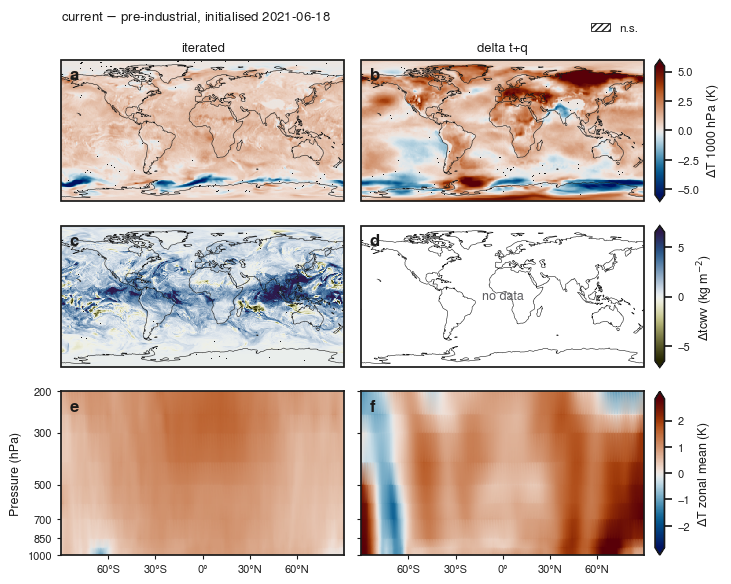

2021-06-22 curr-pi T1000 iterated: 99% of the map significant
2021-06-22 curr-pi T1000 tq: 100% of the map significant
2021-06-22 curr-pi tcwv iterated: 100% of the map significant


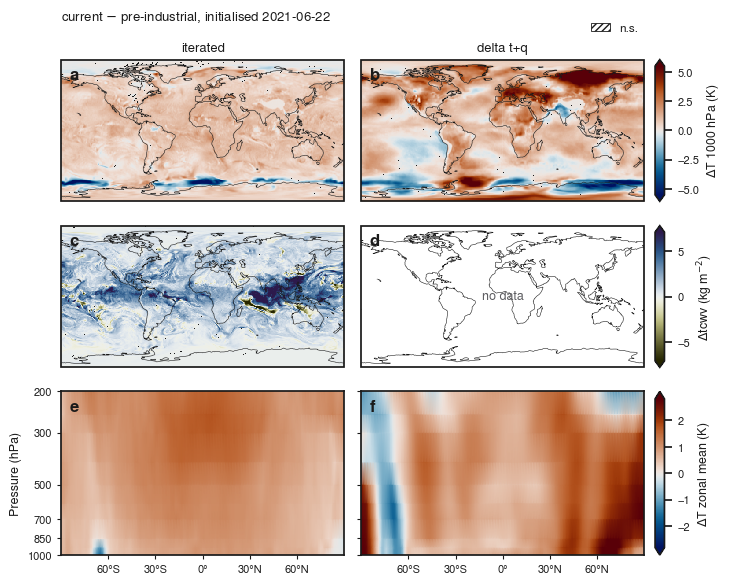

2021-06-26 curr-pi T1000 iterated: 99% of the map significant
2021-06-26 curr-pi T1000 tq: 100% of the map significant
2021-06-26 curr-pi tcwv iterated: 100% of the map significant


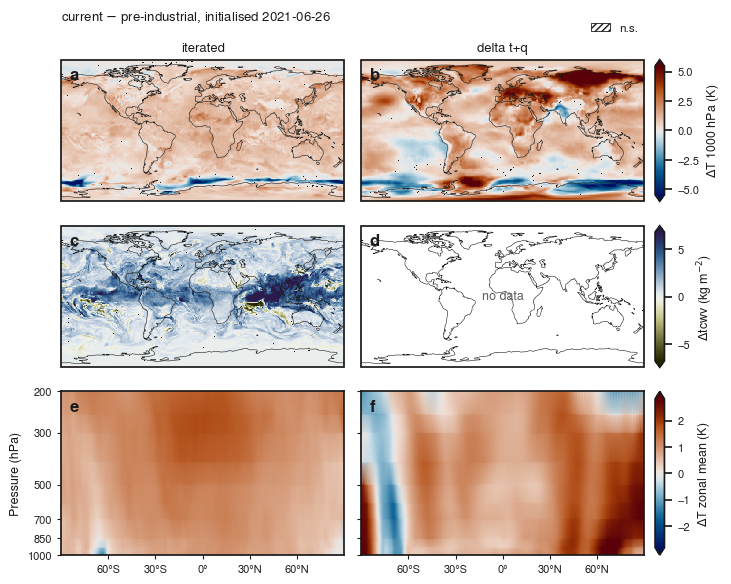

In [10]:
for inidate in ifs_pl.inidate.values:
    signal_at_init('curr', 'pi', inidate)

2021-06-18 incr-curr T1000 iterated: 100% of the map significant
2021-06-18 incr-curr T1000 tq: 100% of the map significant
2021-06-18 incr-curr tcwv iterated: 100% of the map significant


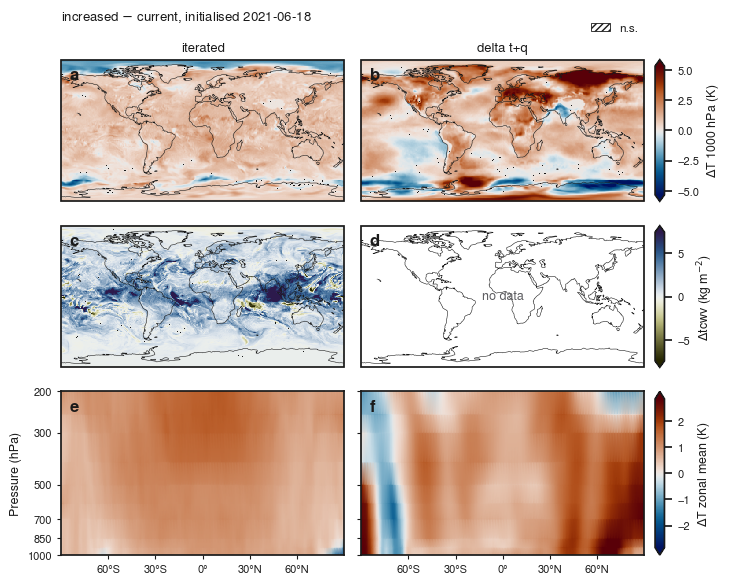

2021-06-22 incr-curr T1000 iterated: 100% of the map significant
2021-06-22 incr-curr T1000 tq: 100% of the map significant
2021-06-22 incr-curr tcwv iterated: 100% of the map significant


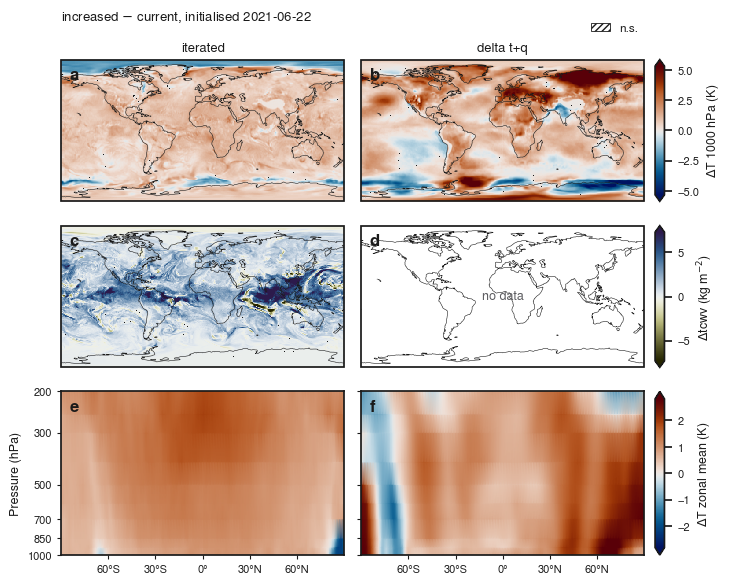

2021-06-26 incr-curr T1000 iterated: 100% of the map significant
2021-06-26 incr-curr T1000 tq: 100% of the map significant
2021-06-26 incr-curr tcwv iterated: 100% of the map significant


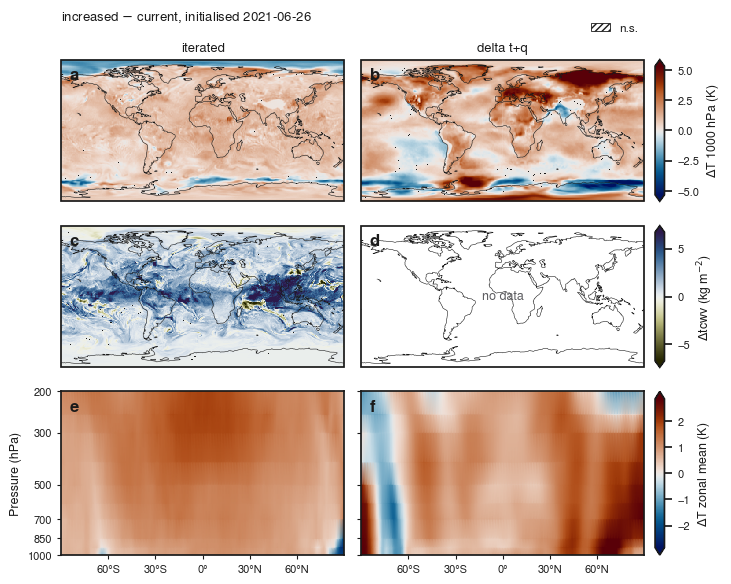

In [11]:
for inidate in ifs_pl.inidate.values:
    signal_at_init('incr', 'curr', inidate)

# Stats

In [8]:
# average temperature signal in each region
region = {'poles': slice(90, 60), 'midlat': slice(60, 30), 'tropics': slice(30, -30),}

In [9]:
# average signal in each latitude band of both hemispheres, split into land and ocean
regions = {'poles': (60, 90), 'midlat': (30, 60), 'tropics': (0, 30)}

lsm = atmicp.Data.get_lsm(res='GLO100').reset_coords(drop=True)
abs_lat = abs(lsm.latitude)
# a grid box at 60° covers half the area of one at the equator
coslat = np.cos(np.deg2rad(lsm.latitude))

SURFACES = {'land': lsm > 0.5, 'ocean': lsm <= 0.5}
AREAS = {f'{region} {surface}': (abs_lat >= lo) & (abs_lat < hi) & mask
         for region, (lo, hi) in regions.items()
         for surface, mask in SURFACES.items()}

In [13]:
inidate = pd.Timestamp('2021-06-26')  # as a string it would also match the 12 UTC surface step
PERTS = ['iterated', 'iterated_short', 'tq']


def region_table(da, name):
    """Area-weighted mean 'curr' - 'pi' signal of `da` in the initial state of
    `inidate`, one row per area and one column per perturbation of the
    pre-industrial run."""
    da = da.sel(inidate=inidate, time=inidate)
    delta = da.sel(climate='curr', perturbation='none', drop=True) - da.sel(climate='pi')
    # the surface fields have no 'tq' run
    delta = delta.sel(perturbation=[p for p in PERTS if p in delta.perturbation.values])
    means = xr.concat(
        [delta.weighted(coslat * mask).mean(['latitude', 'longitude', 'number'])
         for mask in AREAS.values()],
        dim=pd.Index(list(AREAS), name='area'))
    return (means.to_pandas().rename(columns=PERT_LABEL)
            .rename_axis(index=None, columns=name).round(2))


# compare temperature deltas for each area
display(region_table(ifs_pl.t.sel(level=1000), 'ΔT 1000 hPa (K)'))

# compare tcwv deltas for each area
display(region_table(ifs_sfc.tcwv, 'Δtcwv (kg m⁻²)'))

ΔT 1000 hPa (K),iterated,"iterated, short",delta t+q
poles land,0.48,0.45,1.91
poles ocean,-0.27,-0.28,0.44
midlat land,0.73,0.69,1.95
midlat ocean,0.68,0.66,0.75
tropics land,1.04,0.99,1.14
tropics ocean,0.88,0.86,0.72


Δtcwv (kg m⁻²),iterated,"iterated, short"
poles land,0.44,0.38
poles ocean,0.30,0.26
midlat land,1.05,0.90
midlat ocean,0.93,0.84
tropics land,1.93,1.74
tropics ocean,2.42,2.28


In [11]:
# colour tells the variables apart, its weight the two iterated runs
VAR_COLOR = {'T': atmicp.style.accent('indigo'), 'tcwv': atmicp.style.METHOD_COLOR['flow']}
PERT_ALPHA = {'iterated': 1.0, 'iterated_short': 0.45}


def column_water(q):
    """Water vapour between the bottom and top pressure level, in kg m-2."""
    return q.sortby('level').integrate('level') * 100 / 9.81


def area_signal(da, inidate, perts=PERTS):
    """Area-weighted mean 'curr' - 'pi' signal of `da` in the initial state of
    `inidate`, per area and perturbation of the pre-industrial run."""
    da = da.sel(inidate=inidate, time=inidate)
    delta = (da.sel(climate='curr', perturbation='none', drop=True)
             - da.sel(climate='pi', perturbation=perts)).mean('number').load()
    return xr.concat([delta.weighted(coslat * mask).mean(['latitude', 'longitude'])
                      for mask in AREAS.values()],
                     dim=pd.Index(list(AREAS), name='area'))


def signal_bars(inidate):
    """Climate change signal 'curr' - 'pi' of the iterated runs in the initial
    conditions, as a percentage of the signal of the ERA5 delta run ('tq').

    tcwv of the 'tq' run is not on disk on the global grid, so its 100% is the
    water vapour column integrated from q on the pressure levels.

    Returns the percentages as a table, areas down and (variable, perturbation) across.
    """
    signal = {'T': area_signal(ifs_pl.t.sel(level=1000), inidate),
              'tcwv': xr.concat([area_signal(ifs_sfc.tcwv, inidate, PERTS[:2]),
                                 area_signal(column_water(ifs_pl.q), inidate, ['tq'])],
                                dim='perturbation')}
    share = pd.concat({var: (100 * s / s.sel(perturbation='tq')).to_pandas()
                       for var, s in signal.items()}, axis='columns', names=['variable'])
    share = share.drop(columns='tq', level='perturbation')

    fig, ax = plt.subplots(figsize=(atmicp.style.REF_WIDTH, 3.0))
    ax.axhline(100, color=atmicp.style.INK, linestyle=LS['tq'], linewidth=0.9)
    ax.axhline(0, color=atmicp.style.INK, linewidth=0.6)  # some shares are negative

    # land and ocean of one latitude band sit together, the bands a little apart
    x = np.arange(len(AREAS)) + 0.3 * (np.arange(len(AREAS)) // len(SURFACES))
    centre = {var: 0.42 * (i - 0.5) for i, var in enumerate(VAR_COLOR)}
    for var, color in VAR_COLOR.items():
        for j, (pert, alpha) in enumerate(PERT_ALPHA.items()):
            ax.bar(x + centre[var] + 0.17 * (j - 0.5), share[var][pert], width=0.15,
                   color=color, alpha=alpha, linewidth=0)

    # the variable under each pair of bars, the area under each group
    ax.set_xticks(x, [area.replace(' ', '\n') for area in AREAS],
                  fontsize=atmicp.style.FS_LABEL)
    ax.set_xticks(np.concatenate([x + c for c in centre.values()]),
                  np.repeat(list(centre), len(x)), minor=True, fontsize=atmicp.style.FS_TICK)
    ax.tick_params(axis='x', which='major', pad=16)
    ax.tick_params(axis='y', labelsize=atmicp.style.FS_TICK)

    ax.set_ylabel(f'Share of {PERT_LABEL["tq"]} signal (%)', fontsize=atmicp.style.FS_LABEL)
    ax.set_title(f'{LABEL["curr"]} $-$ {LABEL["pi"]}, initialised '
                 f'{pd.Timestamp(inidate):%Y-%m-%d}', loc='left',
                 fontsize=atmicp.style.FS_TITLE)
    ax.legend(handles=[patches.Patch(facecolor=atmicp.style.MUTED, alpha=alpha, linewidth=0,
                                     label=PERT_LABEL[pert])
                       for pert, alpha in PERT_ALPHA.items()]
              + [Line2D([], [], color=atmicp.style.INK, linestyle=LS['tq'], linewidth=0.9,
                        label=PERT_LABEL['tq'])],
              frameon=False, fontsize=atmicp.style.FS_ANNOT)
    sns.despine(ax=ax)

    atmicp.style.save(fig, f'11_signal_bars_curr-pi_{pd.Timestamp(inidate):%Y%m%d}')
    plt.show()

    return share.round(0).astype(int)

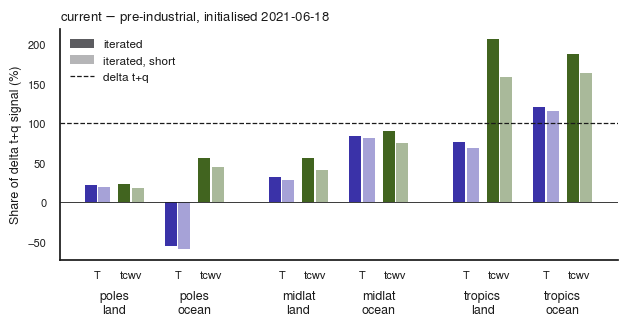

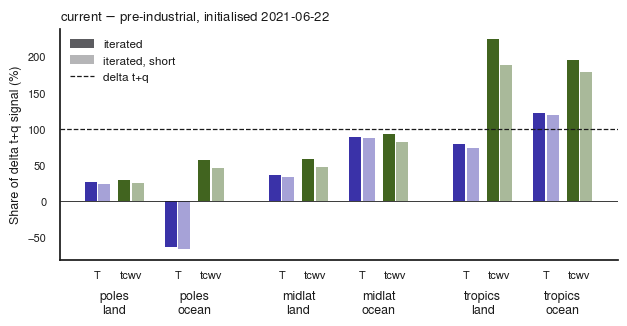

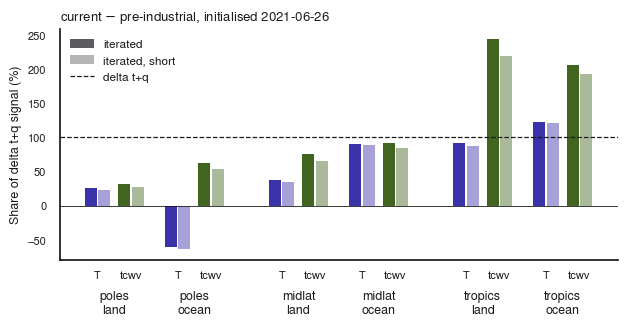

In [12]:
for inidate in ifs_pl.inidate.values:
    signal_bars(inidate)